

## Task 2: Unemployment Analysis with Python

**Name:** Bhushan Hiralal Patel

**Topic:** Unemployment Analysis in India Using Python

### Objective

To analyze unemployment trends in India using Python and data visualization techniques. The main objective is to study unemployment rates across different states and regions, identify monthly trends, compare unemployment before and during the COVID-19 period, and understand the relationship between unemployment, employment and labour participation rates.

### Tools and Technologies Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Dataset
Unemployment in India – Kaggle

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (1).zip


In [3]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/unemployment_data')

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [4]:
os.listdir('/content/unemployment_data')

['Unemployment in India.csv', 'Unemployment_Rate_upto_11_2020.csv']

In [5]:
import pandas as pd

df = pd.read_csv('/content/unemployment_data/Unemployment in India.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
# Display first 5 rows
display(df.head())

# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
display(df.describe())

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data Types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [7]:
# Count rows where every column is missing
print("Completely empty rows:",
      df.isnull().all(axis=1).sum())

# Display rows containing missing values
display(df[df.isnull().any(axis=1)].head(10))

Completely empty rows: 28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Remove completely empty rows
df.dropna(how='all', inplace=True)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nUpdated dataset shape:", df.shape)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Updated dataset shape: (740, 7)


In [9]:
display(df.head())

print("Dataset information:")
df.info()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.2+ KB


In [10]:
# 1. Check all unique states/regions
print("Available Regions:")
print(df['Region'].unique())

# 2. Count the number of regions
print("\nTotal Regions:", df['Region'].nunique())

# 3. Check date range
print("\nStarting Date:", df['Date'].min())
print("Ending Date:", df['Date'].max())

# 4. Check available areas
print("\nArea Categories:")
print(df['Area'].value_counts())

# 5. Check reporting frequency
print("\nFrequency:")
print(df['Frequency'].value_counts())

Available Regions:
['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal' 'Chandigarh']

Total Regions: 28

Starting Date: 2019-05-31 00:00:00
Ending Date: 2020-06-30 00:00:00

Area Categories:
Area
Urban    381
Rural    359
Name: count, dtype: int64

Frequency:
Frequency
Monthly    740
Name: count, dtype: int64


In [11]:
# Calculate average unemployment rate for each region

region_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

display(region_unemployment)

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


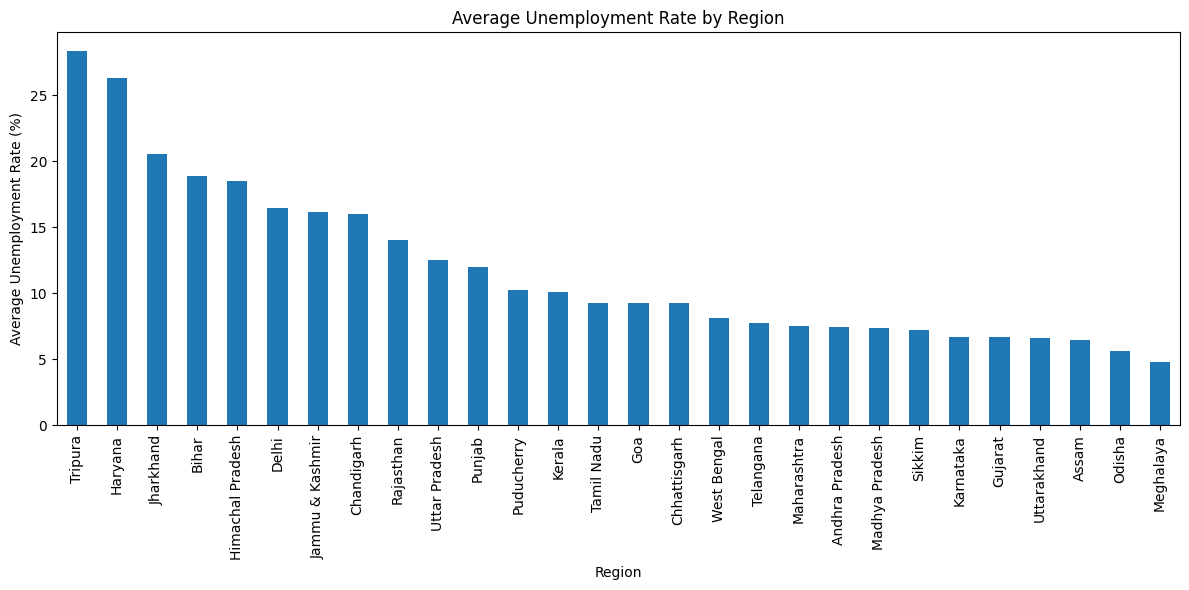

In [12]:
plt.figure(figsize=(12, 6))

region_unemployment.plot(kind='bar')

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

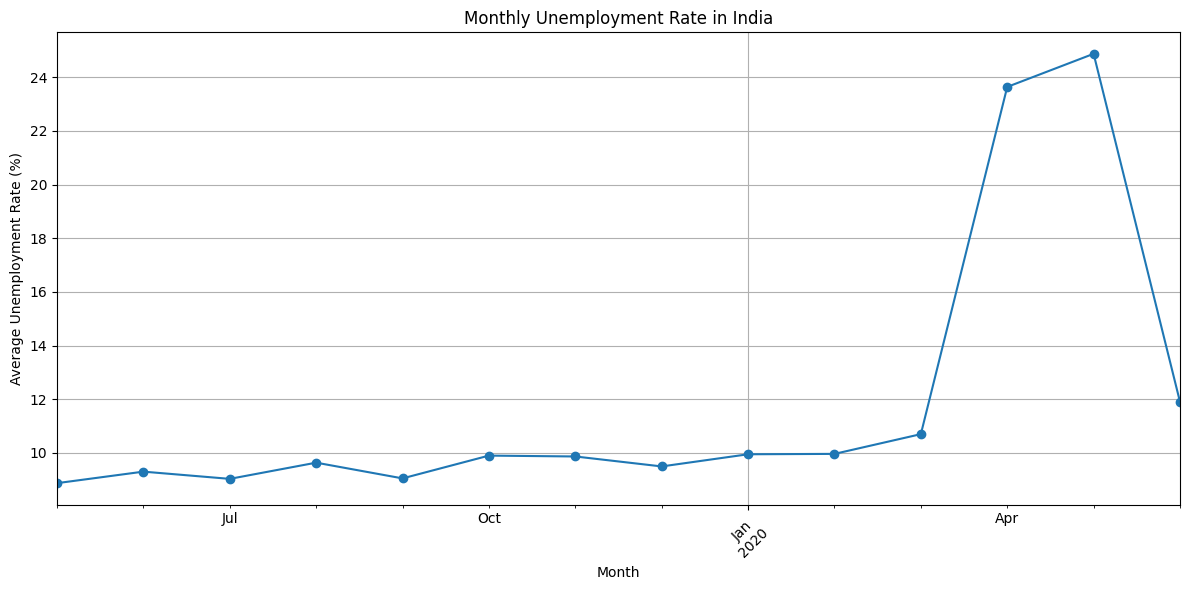

In [13]:
# Convert dates into monthly periods
df['Month'] = df['Date'].dt.to_period('M')

# Calculate average unemployment rate month-wise
monthly_unemployment = df.groupby('Month')[
    'Estimated Unemployment Rate (%)'
].mean()

# Plot monthly trend
plt.figure(figsize=(12, 6))

monthly_unemployment.plot(kind='line', marker='o')

plt.title('Monthly Unemployment Rate in India')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [14]:
top_regions = df['Region'].value_counts().head(3).index.tolist()

print("Selected Regions:", top_regions)

Selected Regions: ['Andhra Pradesh', 'Bihar', 'Chhattisgarh']


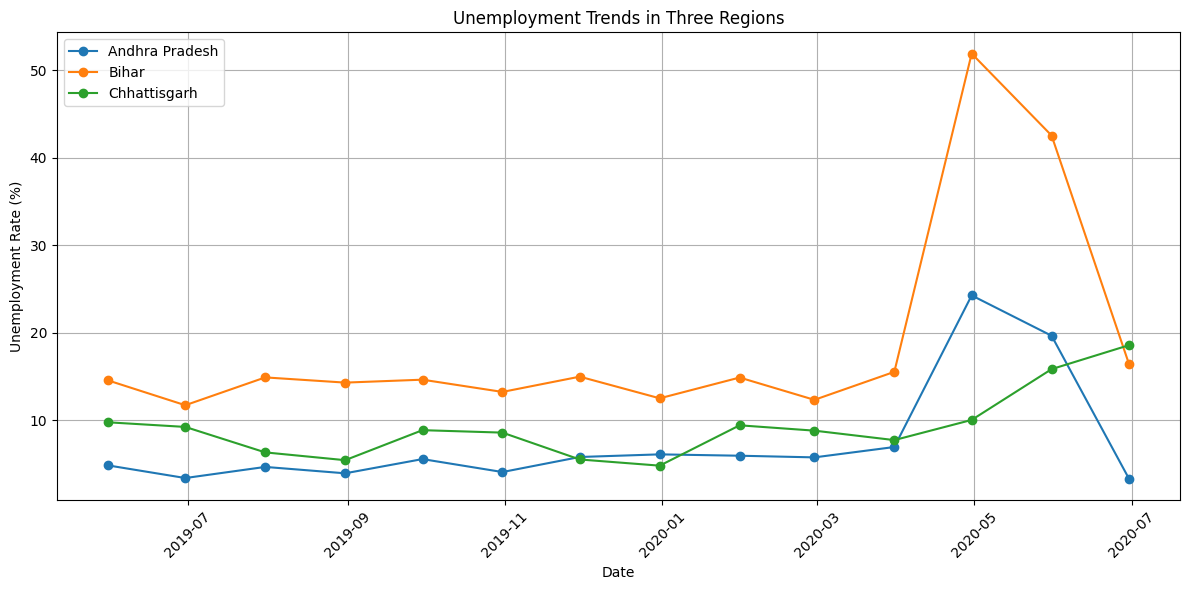

In [15]:
plt.figure(figsize=(12, 6))

for region in top_regions:
    region_data = df[df['Region'] == region]

    monthly_data = region_data.groupby('Date')[
        'Estimated Unemployment Rate (%)'
    ].mean()

    plt.plot(
        monthly_data.index,
        monthly_data.values,
        marker='o',
        label=region
    )

plt.title('Unemployment Trends in Three Regions')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

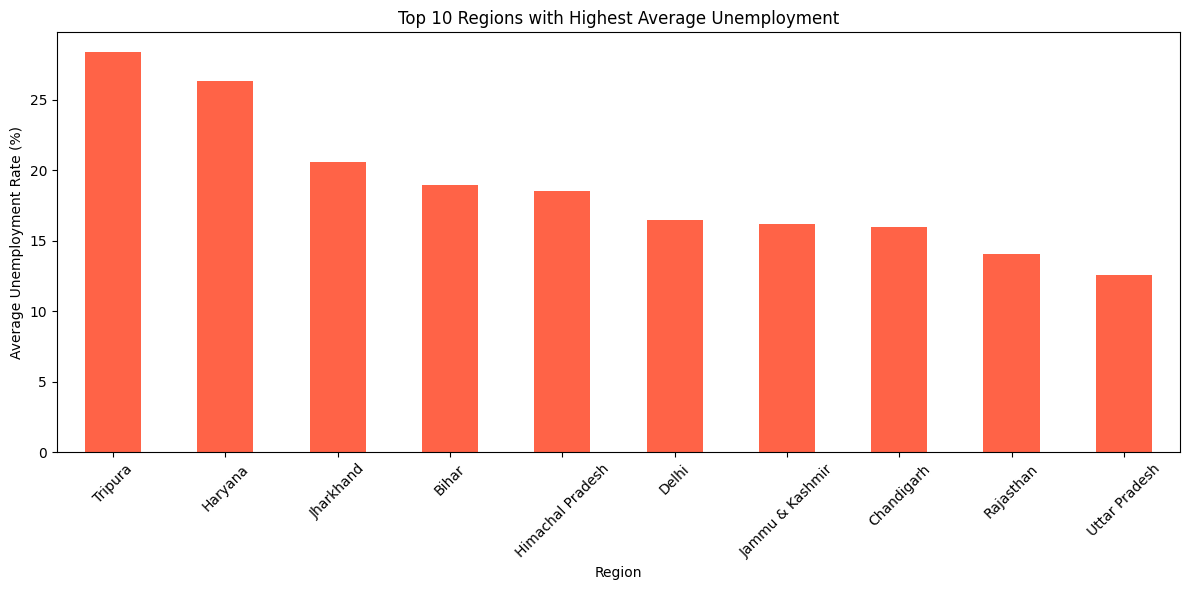

In [16]:
top_10 = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

top_10.plot(kind='bar', color='tomato')

plt.title('Top 10 Regions with Highest Average Unemployment')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

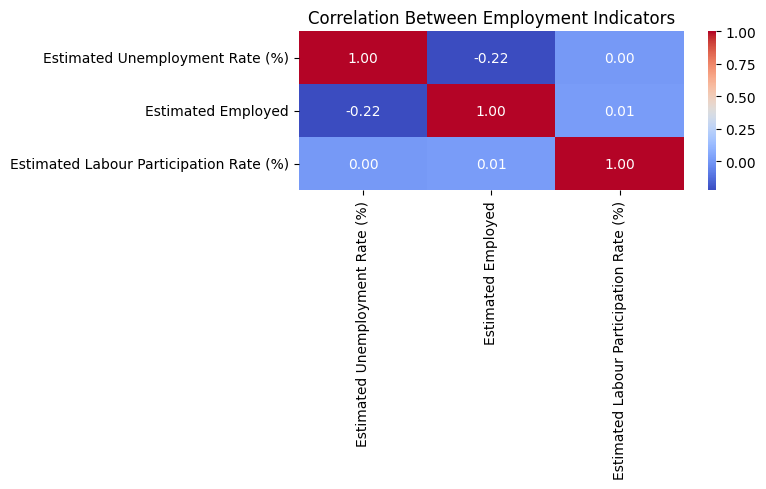

In [17]:
# Select numerical columns
correlation_data = df[
    [
        'Estimated Unemployment Rate (%)',
        'Estimated Employed',
        'Estimated Labour Participation Rate (%)'
    ]
]

# Calculate correlation
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Employment Indicators')
plt.tight_layout()

plt.show()

Pre-COVID Average Unemployment: 9.51 %
During-COVID Average Unemployment: 17.77 %


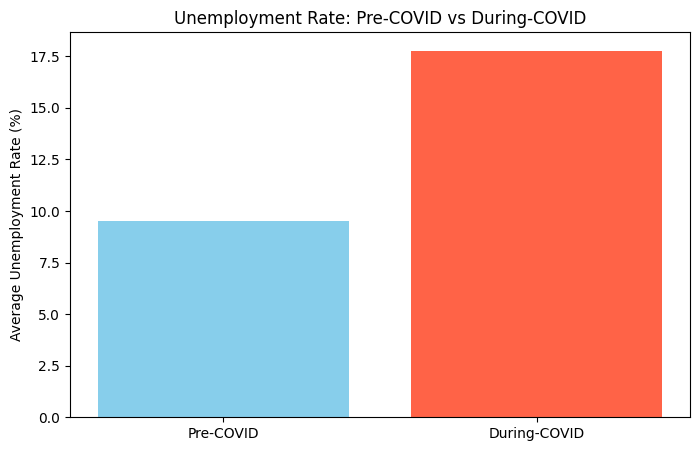

In [18]:
# Separate pre-COVID and during-COVID data
pre_covid = df[df['Date'] < '2020-03-01']

during_covid = df[df['Date'] >= '2020-03-01']

# Calculate average unemployment
pre_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()

covid_avg = during_covid['Estimated Unemployment Rate (%)'].mean()

print("Pre-COVID Average Unemployment:", round(pre_avg, 2), "%")
print("During-COVID Average Unemployment:", round(covid_avg, 2), "%")

# Plot comparison
plt.figure(figsize=(8, 5))

plt.bar(
    ['Pre-COVID', 'During-COVID'],
    [pre_avg, covid_avg],
    color=['skyblue', 'tomato']
)

plt.title('Unemployment Rate: Pre-COVID vs During-COVID')
plt.ylabel('Average Unemployment Rate (%)')

plt.show()

## Conclusion

In this project, I performed an analysis of unemployment in India using Python. I used Pandas, NumPy, Matplotlib and Seaborn for data cleaning, data processing and visualization.

The analysis included region-wise unemployment rates, monthly unemployment trends, comparisons between different regions, correlation between employment indicators, and a comparison of unemployment before and during the COVID-19 period.

This project helped me understand how data analysis and visualization can be used to identify unemployment patterns and trends.